# Physics-Informed Neural Networks used on the 3D Asian Option pricing PDE

### Imports and setup

In [10]:
# Reload pinns_applied_on_3d_pde.py automatically when you edit it, without restarting the kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Make sure the /methods folder is included in the path
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from methods import pinns_applied_on_3d_pde as ap

print(torch.__version__, 'GPU' if torch.cuda.is_available() else 'CPU')

2.10.0+cpu CPU


In [4]:
# Parameters
cfg = ap.Config(
    # training box
    S_max=3.0, I_max=1.0, T=1.0, r_max=0.1, sigma_max=0.5,
    # network
    width=40, depth=4,
    # optimisation
    epochs=50_000, lr=1e-3, n_pde=2000, n_bc=200, w_pde=1.0,
    # misc
    seed=0, log_every=5000,
)
run_dir = 'runs/w40_e40k'
cfg

Config(T=1.0, S_max=3.0, I_max=1.0, r_max=0.1, sigma_max=0.5, width=40, depth=4, normalize_inputs=True, epochs=50000, lr=0.001, n_pde=2000, n_bc=200, w_pde=1.0, seed=0, dtype='float32', log_every=5000, device='cpu')

### Training

In [5]:
model = ap.train(cfg, run_dir)

device=cpu  params=5201  epochs=50000
       1  loss=6.860e-01  pde=1.040e-04  data=6.859e-01  lr=1.00e-03  t=0s
    5000  loss=4.077e-05  pde=2.594e-05  data=1.483e-05  lr=9.76e-04  t=142s
   10000  loss=1.285e-05  pde=6.761e-06  data=6.084e-06  lr=9.05e-04  t=285s
   15000  loss=1.395e-05  pde=8.451e-06  data=5.503e-06  lr=7.94e-04  t=430s
   20000  loss=8.046e-06  pde=3.882e-06  data=4.164e-06  lr=6.55e-04  t=572s
   25000  loss=6.035e-06  pde=2.193e-06  data=3.842e-06  lr=5.00e-04  t=714s
   30000  loss=4.132e-06  pde=1.826e-06  data=2.306e-06  lr=3.45e-04  t=857s
   35000  loss=3.788e-06  pde=1.455e-06  data=2.334e-06  lr=2.06e-04  t=994s
   40000  loss=3.849e-06  pde=1.556e-06  data=2.293e-06  lr=9.55e-05  t=1125s
   45000  loss=3.029e-06  pde=1.227e-06  data=1.802e-06  lr=2.45e-05  t=1259s
   50000  loss=2.868e-06  pde=1.005e-06  data=1.863e-06  lr=0.00e+00  t=1404s
saved to runs\w40_e40k/  (training time 1404s)


Reusing an already trained model

In [6]:
# model, cfg = ap.load_model(run_dir)

### Loss history

Text(0, 0.5, 'MSE')

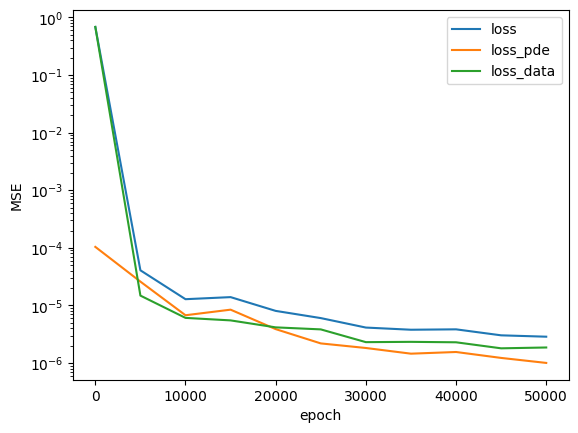

In [7]:
log = pd.read_csv(f'{run_dir}/loss_log.csv')
ax = log.plot(x='epoch', y=['loss', 'loss_pde', 'loss_data'], logy=True)
ax.set_ylabel('MSE')

### Prices against reference

In [8]:
K, r = 100.0, 0.05
ref = pd.DataFrame({
    'S':     [90, 90, 90, 100, 100, 100, 110, 110, 110],
    'sigma': [0.1, 0.2, 0.3] * 3,
    'V_ref': [0.210, 1.576, 3.366, 3.646, 5.787, 7.905, 12.214, 13.049, 14.651],
})
ref['V_pinn'] = [ap.price(model, cfg, [S], K, r, s)[0] for S, s in zip(ref.S, ref.sigma)]
ref['abs_err'] = (ref.V_pinn - ref.V_ref).abs()
print('MAE:', ref.abs_err.mean())
ref.round(3)

MAE: 0.04471178580655


,S,sigma,V_ref,V_pinn,abs_err
0,90,0.1,0.210,0.211,0.001
1,90,0.2,1.576,1.549,0.027
2,90,0.3,3.366,3.342,0.024
3,100,0.1,3.646,3.819,0.173
4,100,0.2,5.787,5.742,0.045
5,100,0.3,7.905,7.919,0.014
6,110,0.1,12.214,12.119,0.095
7,110,0.2,13.049,13.055,0.006
8,110,0.3,14.651,14.633,0.018


### Price and delta curves

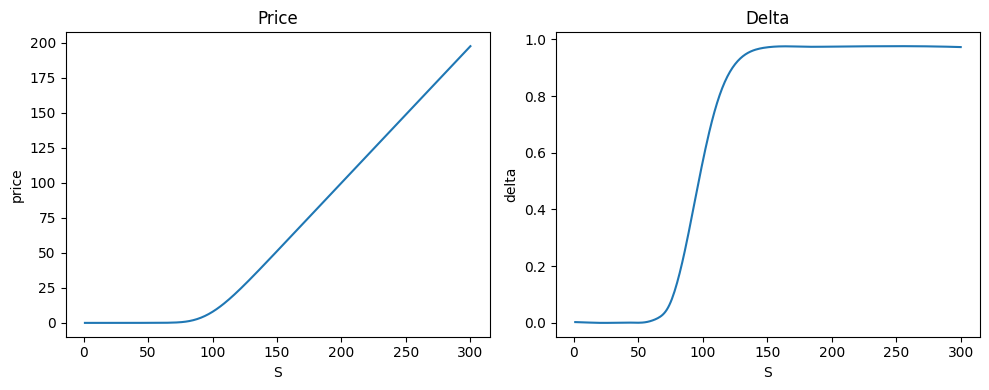

In [9]:
S_grid = np.linspace(1, 300, 300)
V, delta = ap.price_and_delta(model, cfg, S_grid, K=100.0, r=0.05, sigma=0.3)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(S_grid, V);     axes[0].set(xlabel='S', ylabel='price', title='Price')
axes[1].plot(S_grid, delta); axes[1].set(xlabel='S', ylabel='delta', title='Delta')
plt.tight_layout()

### The Greeks

In [ ]:
g = ap.greeks(model, cfg, S=[90, 100, 110], K=100, r=0.05, sigma=0.3)
print(g["delta"])
print(g["gamma"])
print(g["vega"])
print(g["theta"])
print(g["rho"])
print(g["delta_I"])
print(g["dual_delta"])

UFuncTypeError: ufunc 'add' did not contain a loop with signature matching types (dtype('<U7'), dtype('float32')) -> None